Selection of the best hyperparameters of DSLM for each configuration (the model with the highest quality, and the coverage in case of a tie).

It requires the execution of `python mine_phenotypes.py clinical all <number_of_processes>` (DSLM algorithm of the subgroups library).

Inputs: `results/clinical/mining/<configuration>/log/` (one log file per combination of hyperparameters).
Outputs: `results/clinical/grid_results.csv`, `results/clinical/best_models.csv` and `results/clinical/figures/`.

In [1]:
import sys
sys.path.insert(0, "..")
import utils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

In [2]:
view = "clinical"
output_path = utils.PHENOTYPES_RESULTS_PATH / view
figures_path = output_path / "figures"
figures_path.mkdir(parents=True, exist_ok=True)
pattern_quality = "^quality = (?P<quality>[-0-9.e]+)$"
pattern_coverage = "^coverage = (?P<coverage>[-0-9.e]+)$"
pattern_diversity = "^diversity = (?P<diversity>[-0-9.a-z]+)$"
pattern_n = "^number_of_subgroups = (?P<n>[0-9]+)$"

# 1. Read data

In [3]:
list_of_results = []
for configuration in utils.CONFIGURATIONS:
    log_path = utils.mining_path(view, configuration) / "log"
    for file_name in sorted(log_path.iterdir()):
        name_parts = file_name.stem.split("_")
        file_content = file_name.read_text()
        list_of_results.append({
            "configuration" : configuration,
            "beta" : float(name_parts[1]),
            "maximum_positive_overlap" : float(name_parts[2]),
            "maximum_negative_overlap" : float(name_parts[3]),
            "quality" : float(re.search(pattern_quality, file_content, flags=re.M).group("quality")),
            "coverage" : float(re.search(pattern_coverage, file_content, flags=re.M).group("coverage")),
            "diversity" : float(re.search(pattern_diversity, file_content, flags=re.M).group("diversity")),
            "number_of_subgroups" : int(re.search(pattern_n, file_content, flags=re.M).group("n")),
        })
results = pd.DataFrame(list_of_results)
results.to_csv(output_path / "grid_results.csv", index=False)
results.groupby("configuration").size() # It must be 54 for each configuration.

configuration
unit_CCU           54
unit_CSRU          54
unit_MICU          54
unit_NO_ICU        54
unit_SICU          54
unit_TSICU         54
with_context       54
without_context    54
dtype: int64

# 2. Plot results

## Quality (y) vs. coverage (x)

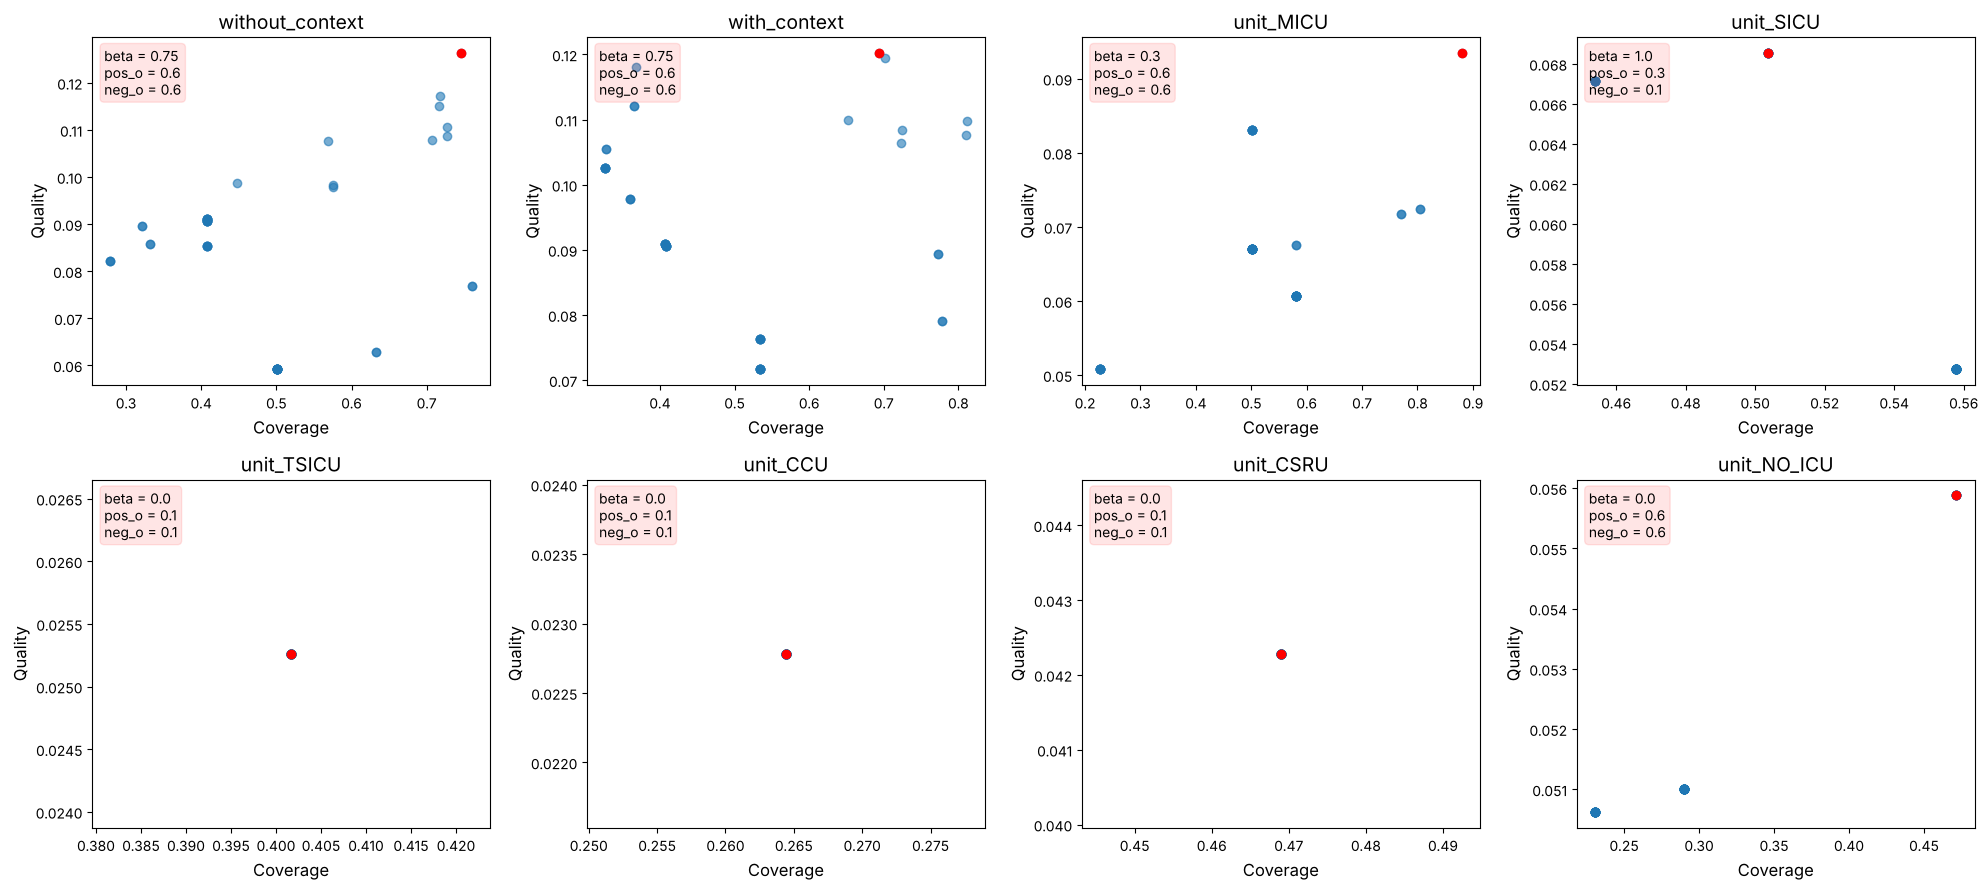

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, configuration in zip(axes.flatten(), utils.CONFIGURATIONS):
    r = results[results["configuration"] == configuration].sort_values("coverage")
    best = r.sort_values(["quality", "coverage"], ascending=False).iloc[0]
    ax.plot(r["coverage"], r["quality"], "o", color="tab:blue", alpha=0.6)
    ax.plot(best["coverage"], best["quality"], "ro")
    ax.set_title(configuration, fontsize=14)
    ax.set_xlabel("Coverage", fontsize=12)
    ax.set_ylabel("Quality", fontsize=12)
    ax.text(0.03, 0.97, "beta = " + str(best["beta"]) + "\npos_o = " + str(best["maximum_positive_overlap"]) + "\nneg_o = " + str(best["maximum_negative_overlap"]),
            transform=ax.transAxes, fontsize=10, verticalalignment="top", bbox=dict(boxstyle="round", alpha=0.1, color="red"))
plt.tight_layout()
plt.savefig(figures_path / "hyperparameters_quality_vs_coverage.pdf")
plt.show()

## Quality (y) vs. beta (x)

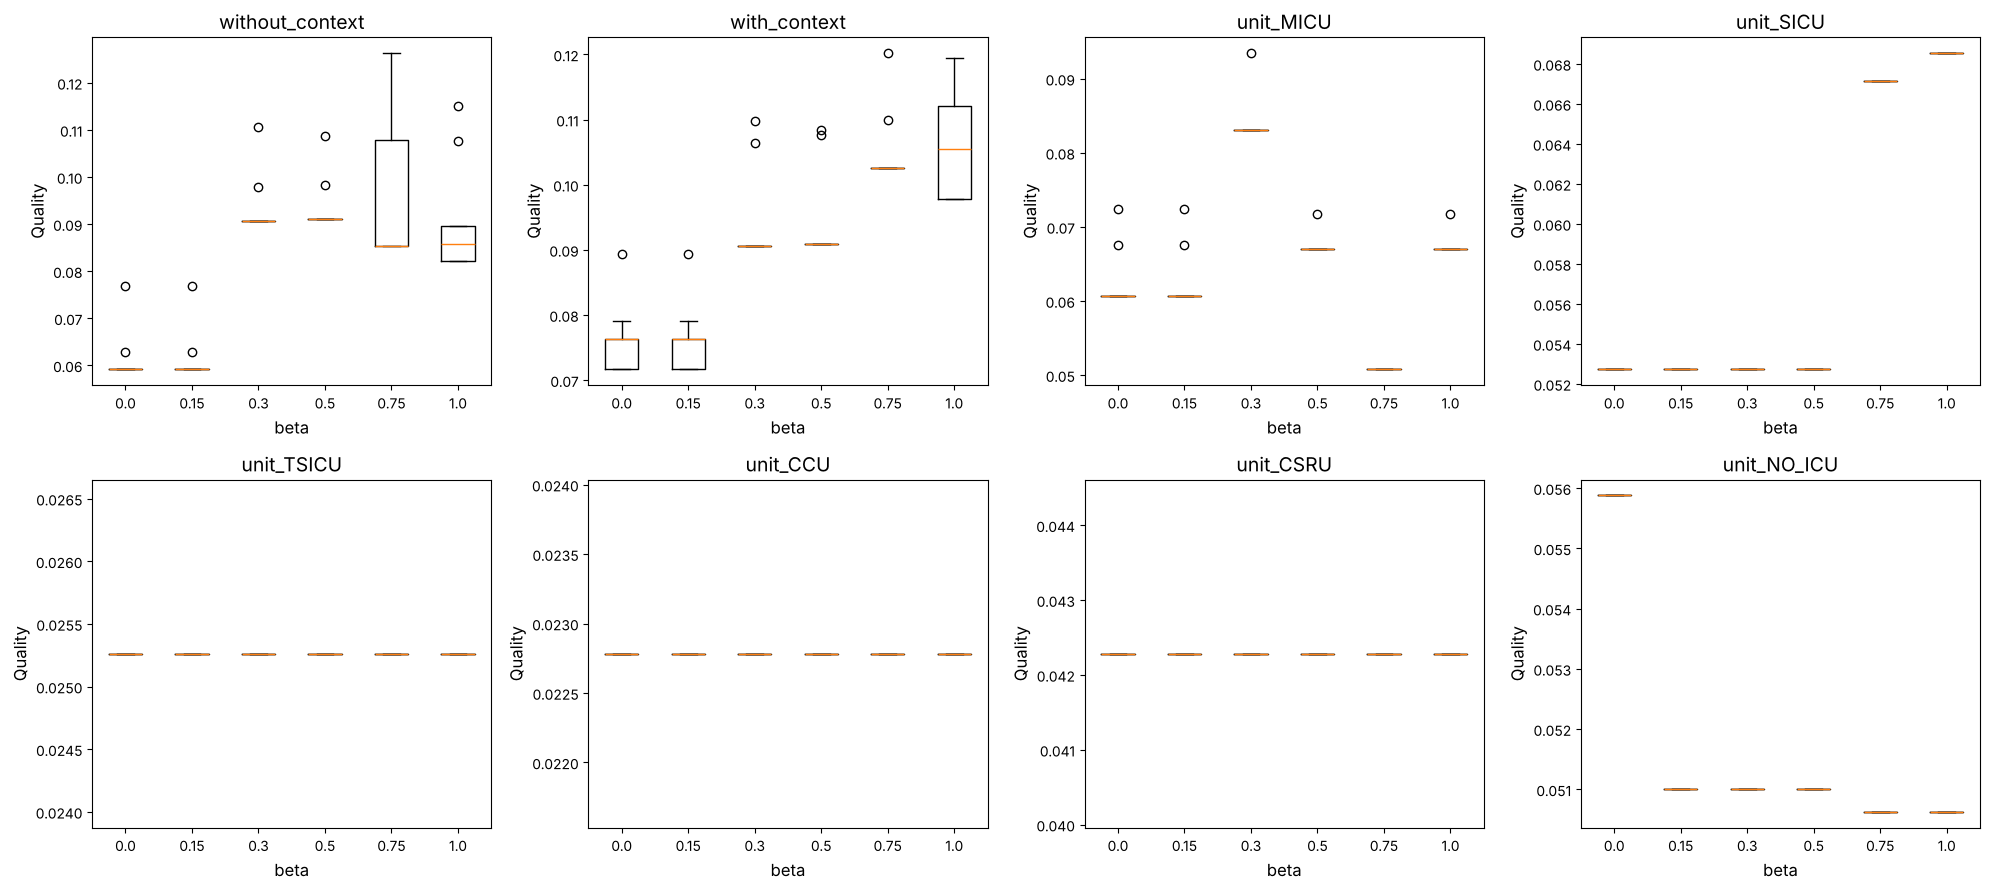

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, configuration in zip(axes.flatten(), utils.CONFIGURATIONS):
    r = results[results["configuration"] == configuration]
    data = [r[r["beta"] == b]["quality"].values for b in utils.GRID["beta"]]
    ax.boxplot(data, tick_labels=utils.GRID["beta"])
    ax.set_title(configuration, fontsize=14)
    ax.set_xlabel("beta", fontsize=12)
    ax.set_ylabel("Quality", fontsize=12)
plt.tight_layout()
plt.show()

# 3. Best model of each configuration

In [6]:
best_models = results.sort_values(["quality", "coverage"], ascending=False).groupby("configuration", sort=False).head(1)
best_models = best_models.set_index("configuration").loc[utils.CONFIGURATIONS].reset_index()
best_models.to_csv(utils.best_models_path(view), index=False)
best_models

,configuration,beta,maximum_positive_overlap,maximum_negative_overlap,quality,coverage,diversity,number_of_subgroups
0,without_context,0.75,0.6,0.6,0.126334,0.746108,0.738095,14
1,with_context,0.75,0.6,0.6,0.120226,0.694212,0.611111,16
2,unit_MICU,0.30,0.6,0.6,0.093467,0.879617,0.766667,5
3,unit_SICU,1.00,0.1,0.1,0.068543,0.503546,0.722222,4
4,unit_TSICU,0.00,0.1,0.1,0.025262,0.401674,1.000000,1
5,unit_CCU,0.00,0.1,0.1,0.022783,0.264423,1.000000,1
6,unit_CSRU,0.00,0.1,0.1,0.042283,0.468966,1.000000,1
7,unit_NO_ICU,0.00,0.1,0.1,0.055878,0.471673,1.000000,3


In [7]:
for _, row in best_models.iterrows():
    name = str(row["beta"]) + "_" + str(row["maximum_positive_overlap"]) + "_" + str(row["maximum_negative_overlap"])
    print("#################### " + row["configuration"] + " (" + name + ") ####################")
    for index, subgroup_list in enumerate(utils.read_subgroup_lists(utils.mining_path(view, row["configuration"]) / "lists" / (name + ".txt"))):
        print("## Subgroup list " + str(index + 1) + " ##")
        for position, description in enumerate(subgroup_list):
            print("  s" + str(position + 1) + ": " + utils.description_to_str(description))
    print()

#################### without_context (0.75_0.6_0.6) ####################


## Subgroup list 1 ##
  s1: [treated_with_vancomycin_in_previous_admissions = 'yes', treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
  s2: [admission_location = 'TRANSFER_FROM_HOSPITAL', readmission = 'no', treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
  s3: [admission_location = 'REFERRAL', treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
  s4: [admission_location = 'REFERRAL', previous_isolation_of_sarm = 'no']
## Subgroup list 2 ##
  s1: [previous_exposure_to_antifungal_agents = 'yes', previous_exposure_to_fluorquinolones = 'yes', treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
  s2: [previous_exposure_to_antifungal_agents = 'no', treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
  s3: [patient_age = 'ADULT', previous_exposure_to_third_generation_cephalosporins = 'no']
  s4: [admission_location = 'REFERRAL', organ_transplant_in_previous_admissions = 'no']
## Su

## Subgroup list 1 ##
  s1: [treated_with_vancomycin_in_previous_admissions = 'yes', treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
## Subgroup list 2 ##
  s1: [hematopoietic_transplant_in_previous_admissions = 'no', treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
  s2: [patient_gender = 'F']
## Subgroup list 3 ##
  s1: [previous_isolation_of_sarm = 'no', treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
  s2: [patient_age = 'ADULT']

#################### unit_SICU (1.0_0.1_0.1) ####################
## Subgroup list 1 ##
  s1: [treated_with_vancomycin_in_previous_admissions = 'yes', treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
## Subgroup list 2 ##
  s1: [previous_exposure_to_fluorquinolones = 'yes', treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
## Subgroup list 3 ##
  s1: [mechanical_ventilation_in_previous_admissions = 'yes', treated_with_vancomycin_in_the_

## Subgroup list 1 ##
  s1: [treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
## Subgroup list 2 ##
## Subgroup list 3 ##

#################### unit_CCU (0.0_0.1_0.1) ####################


## Subgroup list 1 ##
  s1: [treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
## Subgroup list 2 ##
## Subgroup list 3 ##

#################### unit_CSRU (0.0_0.1_0.1) ####################
## Subgroup list 1 ##
  s1: [treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
## Subgroup list 2 ##
## Subgroup list 3 ##

#################### unit_NO_ICU (0.0_0.1_0.1) ####################


## Subgroup list 1 ##
  s1: [treated_with_vancomycin_in_previous_admissions = 'yes']
## Subgroup list 2 ##
  s1: [previous_exposure_to_fluorquinolones = 'yes']
## Subgroup list 3 ##
  s1: [treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']

